# COMP6012 Assignment 4



---
## Task 1: Advertisement Generation

In [1]:
##Step 1: Install libraries

!pip install uv
!uv pip install bitsandbytes
!pip install -q transformers accelerate datasets Pillow sentence-transformers gradio

import torch
import warnings
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from datasets import load_dataset
from transformers import Blip2Processor, Blip2ForConditionalGeneration, BitsAndBytesConfig
from sentence_transformers import SentenceTransformer, util

warnings.filterwarnings('ignore')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')
if device == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.9/24.9 MB 61.5 MB/s eta 0:00:00
Using Python 3.12.13 environment at: /usr
Resolved 32 packages in 295ms
Prepared 1 package in 1.19s
Installed 1 package in 2ms
 + bitsandbytes==0.49.2
Device: cuda
GPU: Tesla T4


README.md:   0%|          | 0.00/397 [00:00<?, ?B/s]

data/train-00000-of-00001-da1d7eb613a82b(…):   0%|          | 0.00/19.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/140 [00:00<?, ? examples/s]

Total images: 140
Columns: ['image', 'text']


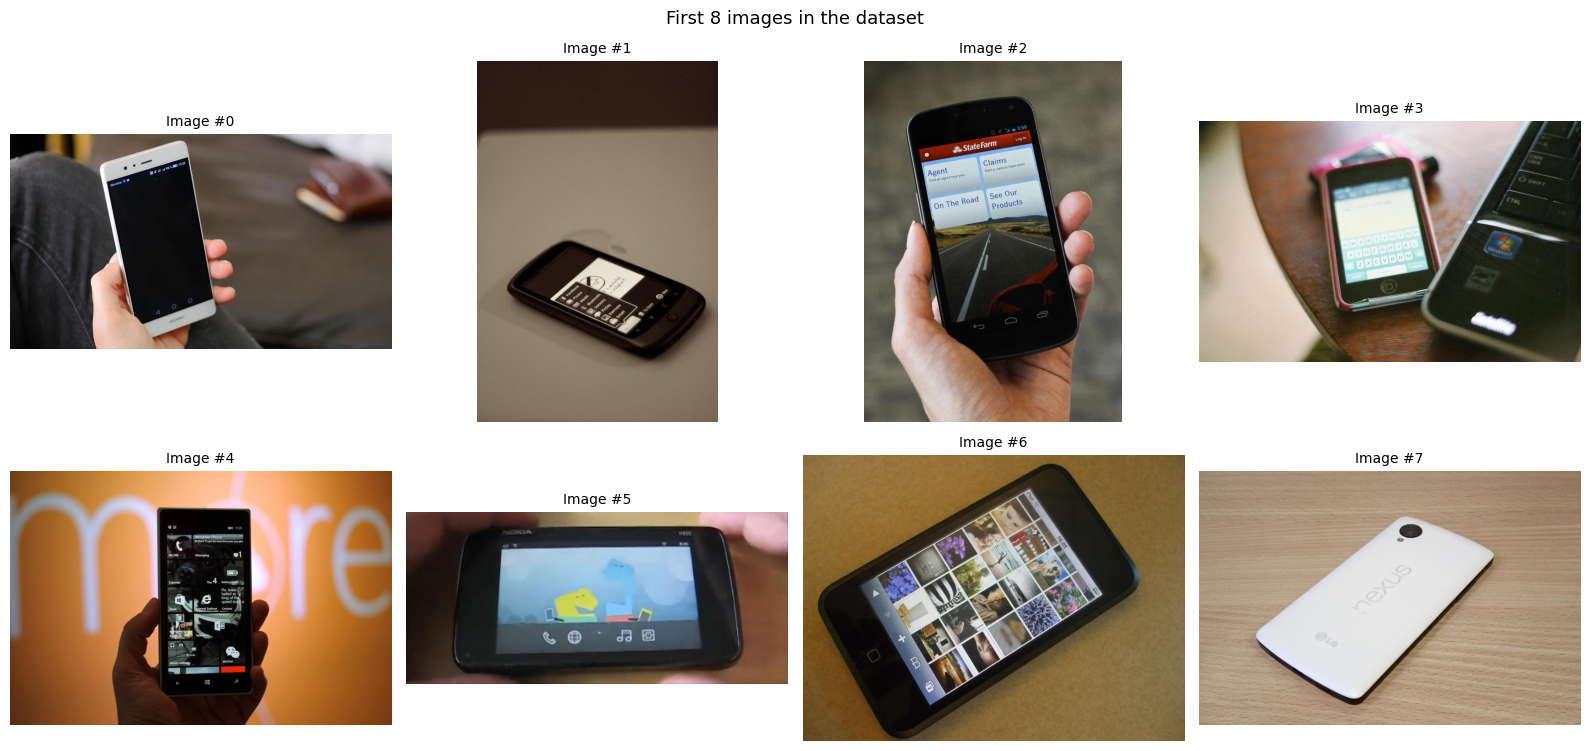

In [2]:
##Step 2: Load the image dataset

# about 140 smartphone images from Hugging Face
dataset = load_dataset('daekeun-ml/mobile-icons-poc', split='train')
print(f'Total images: {len(dataset)}')
print(f'Columns: {dataset.column_names}')

# show the first 8 images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i in range(8):
    img = dataset[i]['image']
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    axes[i].imshow(img)
    axes[i].set_title(f'Image #{i}', fontsize=10)
    axes[i].axis('off')
plt.suptitle('First 8 images in the dataset', fontsize=13)
plt.tight_layout()
plt.savefig('task1_dataset_preview.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
##Step 3: Load BLIP2 model

# 4-bit quantisation to save GPU memory
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

MODEL_NAME = 'Salesforce/blip2-opt-2.7b'

print('Loading BLIP2 processor...')
processor = Blip2Processor.from_pretrained(MODEL_NAME, use_fast=True)
print('Loading BLIP2 model...')
model = Blip2ForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map=device,
    trust_remote_code=True,
    low_cpu_mem_usage=True,
    quantization_config=quantization_config
)
model.eval()

print('Loading sentence similarity model...')
sim_model = SentenceTransformer('all-MiniLM-L6-v2')
print('All models ready.')

Loading BLIP2 processor...


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

All models ready.


In [4]:
##Step 4: Functions for captioning and image matching

def generate_caption(image, text_prompt=None):
    # generate a text description for an image using BLIP2
    if not isinstance(image, Image.Image):
        image = Image.fromarray(image)
    image = image.convert('RGB')
    inputs = processor(
        images=image, text=text_prompt, return_tensors='pt'
    ).to(device, torch.float16)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=50)
    caption = processor.decode(output_ids[0], skip_special_tokens=True).strip()
    return caption


def find_matching_images(prompt, dataset, top_k=1):
    # go through every image, generate a caption, compare it to the prompt
    # return the image with the highest similarity score
    print(f'Searching {len(dataset)} images for: "{prompt}"')
    prompt_emb = sim_model.encode(prompt, convert_to_tensor=True)
    scores = []
    for i, sample in enumerate(dataset):
        caption = generate_caption(sample['image'])
        cap_emb = sim_model.encode(caption, convert_to_tensor=True)
        score = util.cos_sim(prompt_emb, cap_emb).item()
        scores.append((i, score, caption))
        if (i + 1) % 30 == 0:
            print(f'  Done {i+1}/{len(dataset)}...')
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores[:top_k]


# quick test
test_caption = generate_caption(dataset[0]['image'], text_prompt='Describe this image in English')
print(f'Test caption for image #0: {test_caption}')

Test caption for image #0: Describe this image in English



--- Prompt (a) ---
Prompt: Real mobile phones held in hand with the screen clearly visible
Searching 140 images for: "Real mobile phones held in hand with the screen clearly visible"
  Done 30/140...
  Done 60/140...
  Done 90/140...
  Done 120/140...
Best match: Image #6
Score: 0.6154
Caption: a cell phone with pictures on the screen

--- Prompt (b) ---
Prompt: User profile app icons featuring a person silhouette inside a circular avatar
Searching 140 images for: "User profile app icons featuring a person silhouette inside a circular avatar"
  Done 30/140...
  Done 60/140...
  Done 90/140...
  Done 120/140...
Best match: Image #48
Score: 0.6608
Caption: a green and white icon with a person's profile

--- Prompt (c) ---
Prompt: Phone call app icons featuring a white handset symbol on a coloured background
Searching 140 images for: "Phone call app icons featuring a white handset symbol on a coloured background"
  Done 30/140...
  Done 60/140...
  Done 90/140...
  Done 120/140...
Best m

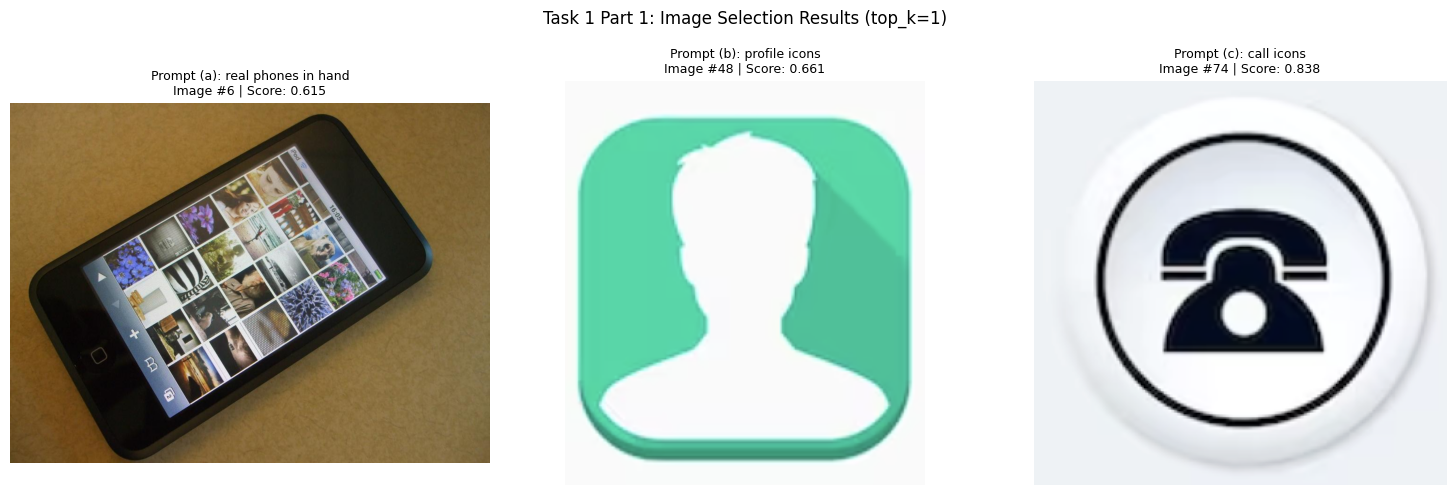

Saved: task1_image_selection.png


In [5]:
##Step 5: Run the three required prompts (top_k=1)

prompts = {
    'a': 'Real mobile phones held in hand with the screen clearly visible',
    'b': 'User profile app icons featuring a person silhouette inside a circular avatar',
    'c': 'Phone call app icons featuring a white handset symbol on a coloured background'
}

selection_results = {}
for key, prompt in prompts.items():
    print(f'\n--- Prompt ({key}) ---')
    print(f'Prompt: {prompt}')
    top = find_matching_images(prompt, dataset, top_k=1)
    selection_results[key] = top[0]
    idx, score, caption = top[0]
    print(f'Best match: Image #{idx}')
    print(f'Score: {score:.4f}')
    print(f'Caption: {caption}')

# show the three matched images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
labels = ['Prompt (a): real phones in hand', 'Prompt (b): profile icons', 'Prompt (c): call icons']
for i, (key, (idx, score, caption)) in enumerate(selection_results.items()):
    img = dataset[idx]['image']
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    axes[i].imshow(img)
    axes[i].set_title(f'{labels[i]}\nImage #{idx} | Score: {score:.3f}', fontsize=9)
    axes[i].axis('off')
plt.suptitle('Task 1 Part 1: Image Selection Results (top_k=1)', fontsize=12)
plt.tight_layout()
plt.savefig('task1_image_selection.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task1_image_selection.png')

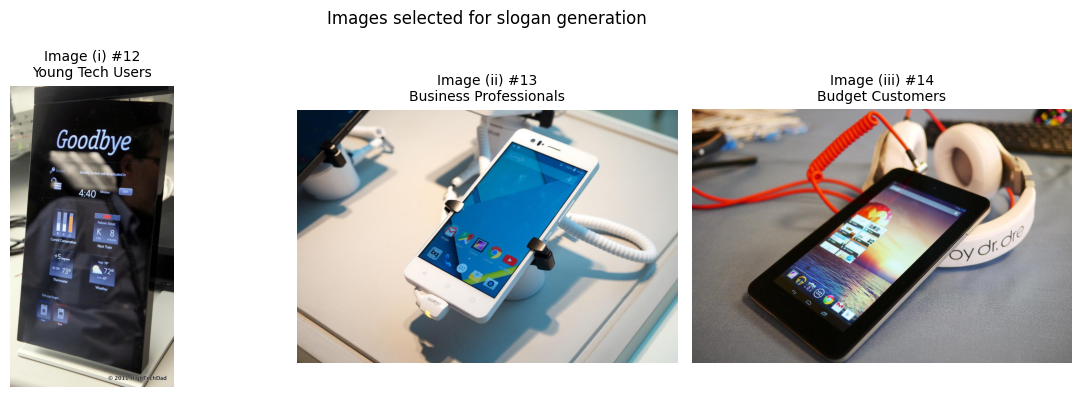


--- Image (i) #12 | Audience: young tech-savvy users ---
User prompt: "Create a slogan for young tech-savvy users"
Caption: the samsung galaxy tab 2 10.1 is the first tablet to feature a built-in digital clock
Slogan: 'Goodbye, goodnight, good morning'

--- Image (ii) #13 | Audience: business professionals ---
User prompt: "Create a slogan for business professionals"
Caption: a white smartphone with a cord attached to it
Slogan: "I'm a professional"

--- Image (iii) #14 | Audience: budget-conscious customers ---
User prompt: "Create a slogan for budget-conscious customers"
Caption: a tablet with headphones and a mouse
Slogan: "The best tablet for the price"


In [6]:
##Step 6: Generate slogans for images #12, #13, #14

selected_images = {
    'i':   {'idx': 12, 'audience': 'young tech-savvy users',     'label': 'Young Tech Users'},
    'ii':  {'idx': 13, 'audience': 'business professionals',     'label': 'Business Professionals'},
    'iii': {'idx': 14, 'audience': 'budget-conscious customers', 'label': 'Budget Customers'}
}

# show the three images first
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, (key, info) in enumerate(selected_images.items()):
    img = dataset[info['idx']]['image']
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    axes[i].imshow(img)
    axes[i].set_title(f'Image ({key}) #{info["idx"]}\n{info["label"]}', fontsize=10)
    axes[i].axis('off')
plt.suptitle('Images selected for slogan generation', fontsize=12)
plt.tight_layout()
plt.savefig('task1_selected_images.png', dpi=150, bbox_inches='tight')
plt.show()


def generate_slogan_blip2(image, audience):
    # get a base caption then ask BLIP2 to write a slogan for the audience
    if not isinstance(image, Image.Image):
        image = Image.fromarray(image)
    image = image.convert('RGB')
    base_caption = generate_caption(image)
    slogan_prompt = (
        f'This is a smartphone product. {base_caption}. '
        f'Create a short sales slogan for {audience}. Slogan:'
    )
    inputs = processor(
        images=image, text=slogan_prompt, return_tensors='pt'
    ).to(device, torch.float16)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=60)
    raw = processor.decode(output_ids[0], skip_special_tokens=True).strip()
    slogan = raw.split('Slogan:')[-1].strip() if 'Slogan:' in raw else raw
    return base_caption, slogan


blip2_slogans = {}
for key, info in selected_images.items():
    img = dataset[info['idx']]['image']
    print(f'\n--- Image ({key}) #{info["idx"]} | Audience: {info["audience"]} ---')
    caption, slogan = generate_slogan_blip2(img, info['audience'])
    blip2_slogans[key] = {'caption': caption, 'slogan': slogan}
    print(f'User prompt: "Create a slogan for {info["audience"]}"')
    print(f'Caption: {caption}')
    print(f'Slogan: {slogan}')

Saved: task1_ad_blip2_i.png
Saved: task1_ad_blip2_ii.png
Saved: task1_ad_blip2_iii.png


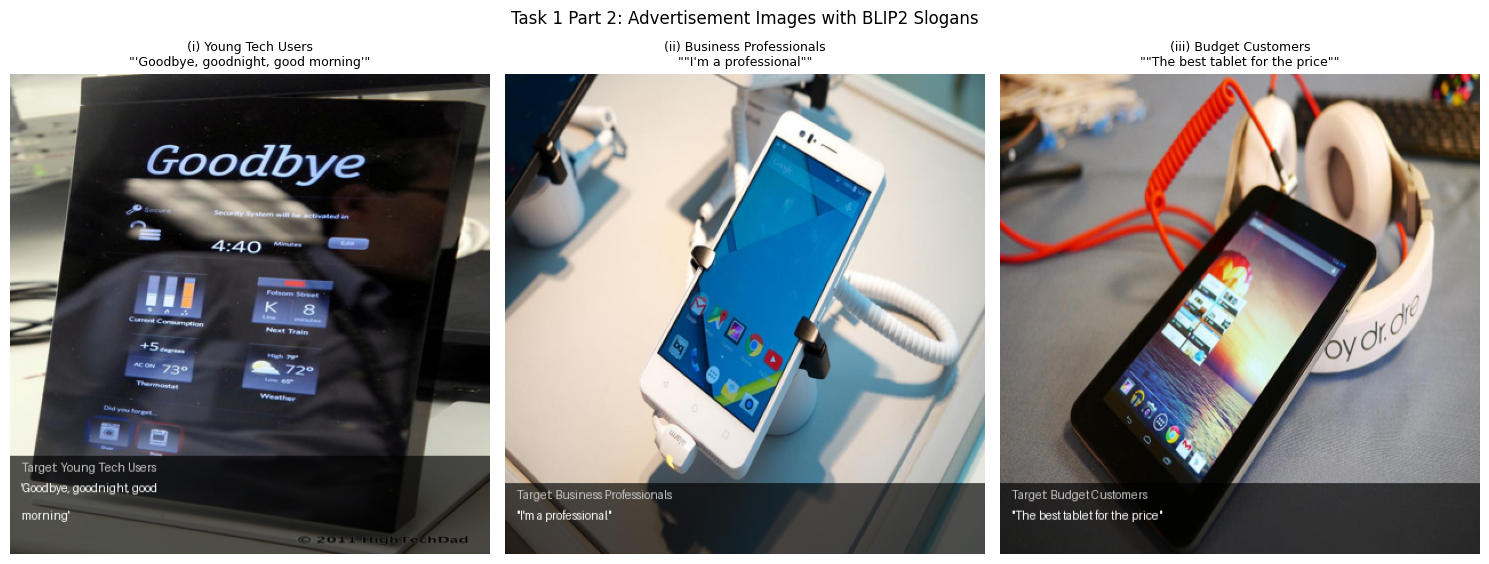

Saved: task1_advertisement_blip2.png


In [7]:
##Step 7: Put slogans on the product images using PIL

def overlay_slogan(image, slogan, audience_label, output_path):
    # resize image, draw a dark banner at the bottom, write the slogan in white
    if not isinstance(image, Image.Image):
        image = Image.fromarray(image)
    img = image.convert('RGB').resize((420, 420))
    try:
        font_big   = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf', 18)
        font_small = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 13)
    except:
        font_big   = ImageFont.load_default()
        font_small = ImageFont.load_default()
    words = slogan.split()
    lines, line = [], []
    for word in words:
        line.append(word)
        if len(' '.join(line)) > 32:
            lines.append(' '.join(line[:-1]))
            line = [word]
    if line:
        lines.append(' '.join(line))
    banner_h   = 30 + len(lines) * 24
    banner_top = 420 - banner_h - 8
    overlay = Image.new('RGBA', img.size, (0, 0, 0, 0))
    ov_draw = ImageDraw.Draw(overlay)
    ov_draw.rectangle([0, banner_top, 420, 420], fill=(0, 0, 0, 170))
    img = Image.alpha_composite(img.convert('RGBA'), overlay).convert('RGB')
    draw = ImageDraw.Draw(img)
    draw.text((10, banner_top + 4), f'Target: {audience_label}', font=font_small, fill=(200, 200, 200))
    for j, line_text in enumerate(lines):
        draw.text((10, banner_top + 22 + j * 24), line_text, font=font_big, fill=(255, 255, 255))
    img.save(output_path)
    return img


ad_images_blip2 = {}
for key, info in selected_images.items():
    img = dataset[info['idx']]['image']
    out_path = f'task1_ad_blip2_{key}.png'
    ad_img = overlay_slogan(img, blip2_slogans[key]['slogan'], info['label'], out_path)
    ad_images_blip2[key] = ad_img
    print(f'Saved: {out_path}')

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for i, (key, ad_img) in enumerate(ad_images_blip2.items()):
    axes[i].imshow(ad_img)
    axes[i].set_title(f'({key}) {selected_images[key]["label"]}\n"{blip2_slogans[key]["slogan"][:40]}"', fontsize=9)
    axes[i].axis('off')
plt.suptitle('Task 1 Part 2: Advertisement Images with BLIP2 Slogans', fontsize=12)
plt.tight_layout()
plt.savefig('task1_advertisement_blip2.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task1_advertisement_blip2.png')

In [8]:
##Step 8: Load Qwen2-VL as the advanced model

# Qwen2-VL connects the vision encoder directly to a stronger language model
# so it writes better and more creative slogans than BLIP2

from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

print('Loading Qwen2-VL-2B...')
qwen_vl_processor = AutoProcessor.from_pretrained('Qwen/Qwen2-VL-2B-Instruct', trust_remote_code=True)
qwen_vl_model = Qwen2VLForConditionalGeneration.from_pretrained(
    'Qwen/Qwen2-VL-2B-Instruct',
    torch_dtype=torch.float16,
    device_map='auto',
    trust_remote_code=True,
    low_cpu_mem_usage=True
)
qwen_vl_model.eval()
print('Qwen2-VL loaded.')

Loading Qwen2-VL-2B...


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Qwen2-VL loaded.


Generating Qwen2-VL slogans...

--- Image (i) #12 | Audience: young tech-savvy users ---
BLIP2:    'Goodbye, goodnight, good morning'
Qwen2-VL: "Stay ahead with our sleek, smart home control device."

--- Image (ii) #13 | Audience: business professionals ---
BLIP2:    "I'm a professional"
Qwen2-VL: "Stay Connected, Stay Ahead: Choose Our Premium Smartphone for Business Professionals"

--- Image (iii) #14 | Audience: budget-conscious customers ---
BLIP2:    "The best tablet for the price"
Qwen2-VL: "Budget-Friendly Bliss: Experience the Ultimate in Convenience and Comfort"



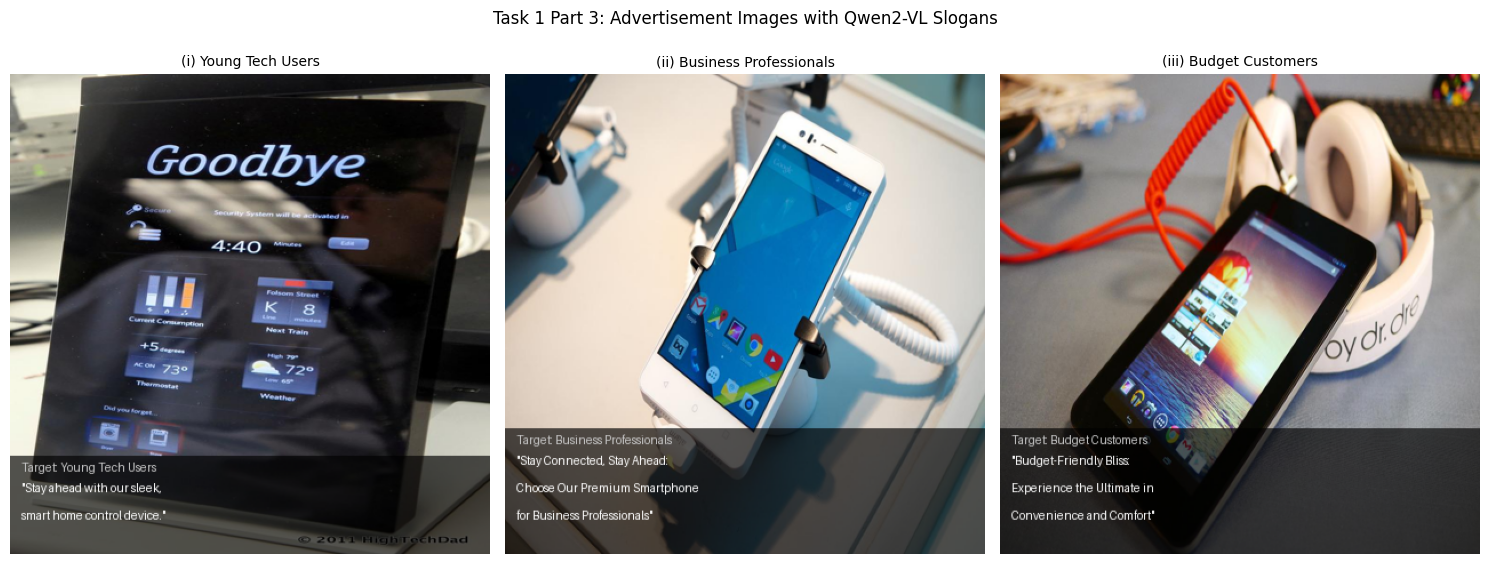

Image    Audience                     BLIP2                Qwen2-VL            
(i)      young tech-savvy users       'Goodbye, goodnigh... "Stay ahead with o...
(ii)     business professionals       "I'm a professiona... "Stay Connected, S...
(iii)    budget-conscious customers   "The best tablet f... "Budget-Friendly B...


In [9]:
def generate_slogan_qwen_vl(image, audience):
    # ask Qwen2-VL to write a slogan for the audience
    if not isinstance(image, Image.Image):
        image = Image.fromarray(image)
    image = image.convert('RGB').resize((336, 336))
    messages = [{
        'role': 'user',
        'content': [
            {'type': 'image', 'image': image},
            {'type': 'text', 'text': (
                f'Look at this smartphone product image. '
                f'Write a short and catchy sales slogan for {audience}. '
                f'Match the tone to what this audience cares about. '
                f'Only output the slogan, nothing else.'
            )}
        ]
    }]
    text = qwen_vl_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = qwen_vl_processor(text=[text], images=[image], return_tensors='pt').to(qwen_vl_model.device)
    with torch.no_grad():
        output_ids = qwen_vl_model.generate(**inputs, max_new_tokens=80, do_sample=True, temperature=0.7)
    generated_ids = [out[len(inp):] for inp, out in zip(inputs.input_ids, output_ids)]
    response = qwen_vl_processor.batch_decode(
        generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=True
    )[0].strip()
    return response


qwen_vl_slogans = {}
print('Generating Qwen2-VL slogans...\n')
for key, info in selected_images.items():
    img = dataset[info['idx']]['image']
    print(f'--- Image ({key}) #{info["idx"]} | Audience: {info["audience"]} ---')
    slogan = generate_slogan_qwen_vl(img, info['audience'])
    qwen_vl_slogans[key] = slogan
    print(f'BLIP2:    {blip2_slogans[key]["slogan"]}')
    print(f'Qwen2-VL: {slogan}')
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for i, (key, info) in enumerate(selected_images.items()):
    img = dataset[info['idx']]['image']
    out_path = f'task1_ad_qwen_{key}.png'
    ad_img = overlay_slogan(img, qwen_vl_slogans[key], info['label'], out_path)
    axes[i].imshow(ad_img)
    axes[i].set_title(f'({key}) {info["label"]}', fontsize=10)
    axes[i].axis('off')
plt.suptitle('Task 1 Part 3: Advertisement Images with Qwen2-VL Slogans', fontsize=12)
plt.tight_layout()
plt.savefig('task1_advertisement_qwen.png', dpi=150, bbox_inches='tight')
plt.show()

print('=' * 80)
print(f'{"Image":<8} {"Audience":<28} {"BLIP2":<20} {"Qwen2-VL":<20}')
print('=' * 80)
for key, info in selected_images.items():
    b2 = blip2_slogans[key]['slogan'][:18] + '...'
    qv = qwen_vl_slogans[key][:18] + '...'
    print(f'{"(" + key + ")":<8} {info["audience"]:<28} {b2:<20} {qv:<20}')
print('=' * 80)

---
## Task 2: Product Recommendation

In [10]:
##Step 1: Import libraries for Task 2

import torch
import pandas as pd
import gradio as gr
import re
import warnings
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

warnings.filterwarnings('ignore')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

Device: cuda


In [11]:
##Step 2: Load the items dataset

# 720 cell phone records
# actual columns: asin, brand, title, url, image, rating, reviewUrl, totalReviews, price, originalPrice
# upload 20191226-items.csv before running this cell

from google.colab import files
import io

print('Please upload 20191226-items.csv')
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df_items = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f'Shape: {df_items.shape}')
print(f'Columns: {list(df_items.columns)}')
df_items.head(3)

Please upload 20191226-items.csv


Saving 20191226-items.csv to 20191226-items (1).csv
Shape: (720, 10)
Columns: ['asin', 'brand', 'title', 'url', 'image', 'rating', 'reviewUrl', 'totalReviews', 'price', 'originalPrice']


,asin,brand,title,url,image,rating,reviewUrl,totalReviews,price,originalPrice
0,B0000SX2UC,NaN,Dual-Band / Tri-Mode Sprint PCS Phone w/ Voice...,https://www.amazon.com/Dual-Band-Tri-Mode-Acti...,https://m.media-amazon.com/images/I/2143EBQ210...,3.0,https://www.amazon.com/product-reviews/B0000SX2UC,14,0.00,0.0
1,B0009N5L7K,Motorola,Motorola I265 phone,https://www.amazon.com/Motorola-i265-I265-phon...,https://m.media-amazon.com/images/I/419WBAVDAR...,3.0,https://www.amazon.com/product-reviews/B0009N5L7K,7,49.95,0.0
2,B000SKTZ0S,Motorola,MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE C...,https://www.amazon.com/MOTOROLA-C168i-CINGULAR...,https://m.media-amazon.com/images/I/71b+q3ydkI...,2.7,https://www.amazon.com/product-reviews/B000SKTZ0S,22,99.99,0.0


In [12]:
##Step 3: Pull out features from the product title

# actual column names from this CSV:
# rating, totalReviews, price  (NOT reviewAverage, reviewCount, price_clean)

def extract_features_from_title(title):
    features = {
        'storage_gb': None, 'camera_mp': None,
        'display_inches': None, 'battery_mah': None
    }
    if not isinstance(title, str):
        return features
    s = re.search(r'(\d+)\s*GB', title, re.IGNORECASE)
    if s: features['storage_gb'] = int(s.group(1))
    c = re.search(r'(\d+)\s*MP', title, re.IGNORECASE)
    if c: features['camera_mp'] = int(c.group(1))
    d = re.search(r'(\d+\.\d+)\s*["|\u2033]|([\d.]+)\s*-?inch', title, re.IGNORECASE)
    if d: features['display_inches'] = float(d.group(1) or d.group(2))
    b = re.search(r'(\d{3,5})\s*mAh', title, re.IGNORECASE)
    if b: features['battery_mah'] = int(b.group(1))
    return features


extracted = df_items['title'].apply(extract_features_from_title).apply(pd.Series)
df_items  = pd.concat([df_items, extracted], axis=1)

# clean price and numeric columns using the REAL column names
df_items['price_usd']    = pd.to_numeric(df_items['price'].replace('[\$,]', '', regex=True), errors='coerce')
df_items['rating']       = pd.to_numeric(df_items['rating'],       errors='coerce')
df_items['totalReviews'] = pd.to_numeric(df_items['totalReviews'], errors='coerce')

print('Done.')
df_items[['brand','title','price_usd','rating','totalReviews','storage_gb','camera_mp']].head(5)

Done.


,brand,title,price_usd,rating,totalReviews,storage_gb,camera_mp
0,NaN,Dual-Band / Tri-Mode Sprint PCS Phone w/ Voice...,0.00,3.0,14,NaN,NaN
1,Motorola,Motorola I265 phone,49.95,3.0,7,NaN,NaN
2,Motorola,MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE C...,99.99,2.7,22,NaN,NaN
3,Motorola,Motorola i335 Cell Phone Boost Mobile,0.00,3.3,21,NaN,NaN
4,Motorola,Motorola V365 no contract cellular phone AT&T,149.99,3.1,12,NaN,NaN


In [13]:
##Step 4: Load TableLLM-7B

# TableLLM is trained to read tables and answer questions about them

print('Loading TableLLM-7b...')
model_name = 'RUCKBReasoning/TableLLM-7b'

try:
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    table_tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    table_model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=torch.float16 if device == 'cuda' else torch.float32,
        device_map='auto',
        quantization_config=quantization_config,
        trust_remote_code=True,
        low_cpu_mem_usage=True
    )
    if device == 'cpu':
        table_model = table_model.to(device)
    table_model.eval()
    print('TableLLM-7b loaded.')
except Exception as e:
    print(f'Error: {e}')

Loading TableLLM-7b...


config.json:   0%|          | 0.00/708 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/893 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

TableLLM-7b loaded.


In [14]:
##Step 5: Functions for searching and recommending phones

def format_table_for_tablellm(df, max_rows=20):
    if len(df) > max_rows:
        df = df.head(max_rows)
        truncated = True
    else:
        truncated = False
    return df.to_string(index=False, max_rows=max_rows), truncated


def analyze_table_with_tablellm(df, question, max_length=512):
    # give the table and question to TableLLM and return its answer
    try:
        table_str, truncated = format_table_for_tablellm(df)
        prompt = f"""Given the following table:

{table_str}

Question: {question}

Please analyze the table and provide a detailed answer:"""

        inputs = table_tokenizer(prompt, return_tensors='pt', truncation=True, max_length=2048)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        with torch.no_grad():
            outputs = table_model.generate(
                **inputs,
                max_new_tokens=max_length,
                temperature=0.7,
                do_sample=True,
                pad_token_id=table_tokenizer.eos_token_id,
                repetition_penalty=1.1
            )
        response = table_tokenizer.decode(outputs[0], skip_special_tokens=True)
        generated_text = response[len(prompt):].strip()
        if truncated:
            generated_text = f'Note: table was cut to first 20 rows.\n\n{generated_text}'
        return generated_text
    except Exception as e:
        return f'Error: {str(e)}'

In [15]:
##Step 6: Run the three required search prompts

# using the correct column names from the actual CSV
df_for_llm = df_items[[
    'brand', 'title', 'price_usd', 'rating',
    'totalReviews', 'storage_gb', 'camera_mp'
]].dropna(subset=['rating']).reset_index(drop=True)

search_prompts = {
    'a': 'I want to find cellphones with a rating above 4.8 and more than 10 reviews.',
    'b': 'I want to find cellphones from Apple with a rating above 4.8.',
    'c': 'I want to find cellphones priced less than 100 dollars with a rating above 4.5.'
}

search_results = {}
for key, question in search_prompts.items():
    print(f'\n=== Prompt ({key}) ===')
    print(f'User: {question}')
    result = analyze_table_with_tablellm(df_for_llm, question, max_length=400)
    search_results[key] = result
    print(f'TableLLM:\n{result}')


=== Prompt (a) ===
User: I want to find cellphones with a rating above 4.8 and more than 10 reviews.
TableLLM:
Note: table was cut to first 20 rows.

import pandas as pd

# Load the data
df = pd.read_csv('data.csv')

# Preprocess the data: Remove rows with missing ratings or reviews
df = df.dropna(subset=['rating', 'totalReviews'])

# Filter the data: Select cellphones with a rating above 4.8 and more than 10 reviews
filtered_df = df[(df['rating'] > 4.8) & (df['totalReviews'] > 10)]

# Output the result
print(filtered_df)

=== Prompt (b) ===
User: I want to find cellphones from Apple with a rating above 4.8.
TableLLM:
Note: table was cut to first 20 rows.

import pandas as pd

# Load the data
df = pd.read_csv('data.csv')

# Filter the data for cellphones from Apple with a rating above 4.8
apple_cellphones = df[(df['brand'] == 'Apple') & (df['rating'] > 4.8)]

 print(apple_cellphones)

=== Prompt (c) ===
User: I want to find cellphones priced less than 100 dollars with a rating above 4

In [16]:
##Step 7: Run three recommendation prompts (i), (ii), (iii)

rec_prompts = {
    'i':   'I need a phone with a great camera and large storage. Which one do you recommend and why?',
    'ii':  'I want a budget phone under 150 dollars with good reviews. Which one would you recommend?',
    'iii': 'I want a Samsung phone with a large screen and good battery life. What do you recommend?'
}

rec_results_tablellm = {}
for key, question in rec_prompts.items():
    print(f'\n=== Recommendation ({key}) ===')
    print(f'User: {question}')
    result = analyze_table_with_tablellm(df_for_llm, question, max_length=512)
    rec_results_tablellm[key] = result
    print(f'TableLLM:\n{result}')


=== Recommendation (i) ===
User: I need a phone with a great camera and large storage. Which one do you recommend and why?
TableLLM:
Note: table was cut to first 20 rows.

1. What are the necessary columns to answer the question?
   - The necessary columns to answer the question are "brand", "title", "price_usd", "rating", "totalReviews", "storage_gb", and "camera_mp".

2. Filtering the DataFrame
   - To filter the DataFrame based on the question requirements, we need to look for phones with a great camera and large storage.
   - We can combine multiple conditions using boolean indexing.
   - Condition 1: Camera rating must be at least 4.
   - Condition 2: Storage size must be at least 128 GB.
   - Update: We can use the "loc" function to select rows based on these conditions.
   - Recommended Phone: Samsung Galaxy Ace III with a camera rating of 4 and storage size of 128 GB.

3. Analyzing the DataFrame
   - The recommended phone, Samsung Galaxy Ace III, has a camera rating of 4 and a

In [17]:
##Step 8: Gradio interface for the recommendation system

import gradio as gr

def get_dataset_info(df):
    lines = []
    lines.append('CELL PHONE DATASET SUMMARY')
    lines.append('=' * 50)
    lines.append(f'Total phones: {len(df):,}')
    lines.append(f'Brands: {df["brand"].nunique()} unique')
    lines.append(f'Price range: ${df["price_usd"].min():.0f} to ${df["price_usd"].max():.0f}')
    lines.append(f'Rating range: {df["rating"].min():.1f} to {df["rating"].max():.1f}')
    lines.append('')
    lines.append('Top 5 brands:')
    for brand, count in df['brand'].value_counts().head(5).items():
        lines.append(f'  {brand}: {count} phones')
    lines.append('')
    lines.append('Sample rows:')
    lines.append('-' * 50)
    lines.append(df[['brand','title','price_usd','rating']].head(5).to_string(index=False))
    return '\n'.join(lines)


def process_query(question, max_length):
    if not question.strip():
        return 'Please type a question.', ''
    dataset_info = get_dataset_info(df_for_llm)
    result = analyze_table_with_tablellm(df_for_llm, question, max_length=max_length)
    return dataset_info, result


sample_questions = [
    'I want to find cellphones with a rating above 4.8 and more than 10 reviews.',
    'I want to find cellphones from Apple with a rating above 4.8.',
    'I want to find cellphones priced less than 100 dollars with a rating above 4.5.',
    'I need a phone with a great camera and large storage. Which one do you recommend?',
    'I want a budget phone under 150 dollars with good reviews. Recommend one.',
    'I want a Samsung phone with a large screen and good battery. What do you recommend?'
]

with gr.Blocks(title='Cell Phone Finder', theme=gr.themes.Soft()) as iface:
    gr.Markdown('# Cell Phone Finder and Recommendation')
    gr.Markdown('Powered by TableLLM-7B | COMP6012 Assignment 4')
    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown('### Your Question')
            sample_q = gr.Dropdown(choices=sample_questions, value=sample_questions[0], label='Pick a sample question')
            question_box = gr.Textbox(value=sample_questions[0], label='Or type your own question', placeholder='Describe the phone you want...', lines=3)
            length_slider = gr.Slider(minimum=128, maximum=1024, value=512, step=64, label='Max response length')
            btn = gr.Button('Search / Recommend', variant='primary', size='lg')
        with gr.Column(scale=2):
            gr.Markdown('### Dataset Overview')
            info_box = gr.Textbox(label='Dataset Info', lines=15, max_lines=20, show_copy_button=True, interactive=False)
            gr.Markdown('### TableLLM Answer')
            result_box = gr.Textbox(label='Result', lines=12, max_lines=20, show_copy_button=True)
    sample_q.change(fn=lambda q: q, inputs=[sample_q], outputs=[question_box])
    btn.click(fn=process_query, inputs=[question_box, length_slider], outputs=[info_box, result_box])

iface.launch(share=True, debug=False)
print('Gradio launched.')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c71388dfb30e624233.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Gradio launched.


In [18]:
##Step 9: Load Mistral-7B-Instruct as the advanced model

# clear GPU memory before loading Mistral
import gc
try:
    del qwen_vl_model
except: pass
gc.collect()
torch.cuda.empty_cache()
print('GPU memory cleared.')

print('Loading Mistral-7B-Instruct-v0.2...')
mistral_name = 'mistralai/Mistral-7B-Instruct-v0.2'

try:
    import os
    os.makedirs('offload', exist_ok=True)
    q_config_m = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    mistral_tokenizer = AutoTokenizer.from_pretrained(mistral_name, trust_remote_code=True)
    mistral_model = AutoModelForCausalLM.from_pretrained(
        mistral_name,
        torch_dtype=torch.float16,
        device_map='auto',
        quantization_config=q_config_m,
        trust_remote_code=True,
        low_cpu_mem_usage=True,
        offload_folder='offload'
    )
    mistral_model.eval()
    print('Mistral loaded.')
except Exception as e:
    print(f'Error: {e}')

GPU memory cleared.
Loading Mistral-7B-Instruct-v0.2...


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/25.1k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Mistral loaded.


In [19]:
def recommend_with_mistral(question, df):
    # give Mistral a sample of the phone table and ask for a recommendation
    sample_rows = df[[
        'brand', 'title', 'price_usd', 'rating',
        'totalReviews', 'storage_gb', 'camera_mp'
    ]].dropna().head(15).to_string(index=False)
    messages = [{
        'role': 'user',
        'content': (
            f'You are a helpful phone shop assistant. '
            f'Here are some phones we have in stock:\n\n'
            f'{sample_rows}\n\n'
            f'Customer request: "{question}"\n\n'
            f'Recommend the best matching phone and explain in 3 to 4 sentences why it suits this customer.'
        )
    }]
    text = mistral_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = mistral_tokenizer(text, return_tensors='pt', truncation=True, max_length=2048)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = mistral_model.generate(
            **inputs, max_new_tokens=200, temperature=0.7, do_sample=True,
            pad_token_id=mistral_tokenizer.eos_token_id, repetition_penalty=1.1
        )
    response = mistral_tokenizer.decode(outputs[0], skip_special_tokens=True)
    return response[len(text):].strip()


print('Comparing TableLLM-7B vs Mistral-7B-Instruct:\n')
for key, question in rec_prompts.items():
    print(f'--- Prompt ({key}): {question} ---')
    print('TableLLM:')
    print(rec_results_tablellm[key][:300])
    print('\nMistral:')
    print(recommend_with_mistral(question, df_for_llm)[:300])
    print()

Comparing TableLLM-7B vs Mistral-7B-Instruct:

--- Prompt (i): I need a phone with a great camera and large storage. Which one do you recommend and why? ---
TableLLM:
Note: table was cut to first 20 rows.

1. What are the necessary columns to answer the question?
   - The necessary columns to answer the question are "brand", "title", "price_usd", "rating", "totalReviews", "storage_gb", and "camera_mp".

2. Filtering the DataFrame
   - To filter the DataFrame base

Mistral:
ed on your requirement for a phone with a great camera and large storage, I would recommend the Samsung Galaxy S6 G920A. This phone offers an impressive 16 megapixel camera and a generous 32 gigabytes of internal storage. It is also an unlocked GSM phone, allowing you to use it with various carriers

--- Prompt (ii): I want a budget phone under 150 dollars with good reviews. Which one would you recommend? ---
TableLLM:
Note: table was cut to first 20 rows.

import pandas as pd

# Load the data
df = pd.read_csv('data.

---
## Task 3: Customer Review Analysis

In [20]:
##Step 1: Import libraries for Task 3

import torch
import pandas as pd
import numpy as np
import re
import warnings
import matplotlib.pyplot as plt
import gradio as gr
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

warnings.filterwarnings('ignore')
set_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

Device: cuda


In [21]:
##Step 2: Load the reviews dataset

# 67,986 Amazon cell phone reviews
# actual columns: asin, name, rating, date, verified, title, body, helpfulVotes
# upload 20191226-reviews.csv before running this cell

from google.colab import files
import io

print('Please upload 20191226-reviews.csv')
uploaded_r = files.upload()
filename_r = list(uploaded_r.keys())[0]
df_reviews = pd.read_csv(io.BytesIO(uploaded_r[filename_r]))

print(f'Shape: {df_reviews.shape}')
print(f'Columns: {list(df_reviews.columns)}')
print(f'\nRating counts:')
print(df_reviews['rating'].value_counts().sort_index())
print(f'\nVerified counts:')
print(df_reviews['verified'].value_counts())
df_reviews.head(3)

Please upload 20191226-reviews.csv


Saving 20191226-reviews.csv to 20191226-reviews (1).csv
Shape: (67986, 8)
Columns: ['asin', 'name', 'rating', 'date', 'verified', 'title', 'body', 'helpfulVotes']

Rating counts:
rating
1    12743
2     3915
3     4752
4     8824
5    37752
Name: count, dtype: int64

Verified counts:
verified
True     61225
False     6761
Name: count, dtype: int64


,asin,name,rating,date,verified,title,body,helpfulVotes
0,B0000SX2UC,Janet,3,"October 11, 2005",False,"Def not best, but not worst",I had the Samsung A600 for awhile which is abs...,1.0
1,B0000SX2UC,Luke Wyatt,1,"January 7, 2004",False,Text Messaging Doesn't Work,Due to a software issue between Nokia and Spri...,17.0
2,B0000SX2UC,Brooke,5,"December 30, 2003",False,Love This Phone,"This is a great, reliable phone. I also purcha...",5.0


Sentiment counts for all 67,986 reviews:
true_sentiment
positive    46576
negative    16658
neutral      4752
Name: count, dtype: int64


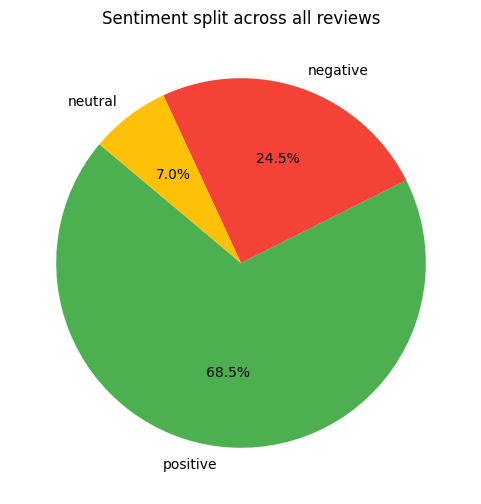

Saved: task3_sentiment_pie.png


In [22]:
##Step 3: Label each review as positive, neutral, or negative

# rating 4 or 5 = positive
# rating 3      = neutral
# rating 1 or 2 = negative

def assign_sentiment(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'


df_reviews['true_sentiment'] = df_reviews['rating'].apply(assign_sentiment)

print('Sentiment counts for all 67,986 reviews:')
print(df_reviews['true_sentiment'].value_counts())

counts = df_reviews['true_sentiment'].value_counts()
colours = ['#4CAF50', '#F44336', '#FFC107']
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=colours, startangle=140)
plt.title('Sentiment split across all reviews', fontsize=12)
plt.savefig('task3_sentiment_pie.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task3_sentiment_pie.png')

In [23]:
##Step 4: Load Qwen3-4B

# clear GPU memory first
import gc
try:
    del mistral_model
    del table_model
except: pass
gc.collect()
torch.cuda.empty_cache()
print('GPU memory cleared.')

model_name = 'Qwen/Qwen3-4B'

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print('Loading tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'

print('Loading model...')
qwen_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map='auto',
    trust_remote_code=True,
    quantization_config=quantization_config
)
print(f'Qwen3-4B loaded.')

GPU memory cleared.
Loading tokenizer...


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen3-4B loaded.


In [24]:
##Step 5: Sentiment analysis function

def analyze_sentiment(review_text, model, tokenizer):
    # ask the model to classify the review as positive, negative, or neutral
    prompt = f"""Classify the sentiment of the following review as one word: positive, negative or neutral.
            Review: "{review_text}"
            Only output one word."""
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=10, temperature=0.1, do_sample=True,
            pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id,
            return_dict_in_generate=True
        )
    generated_sequence = outputs.sequences[0] if hasattr(outputs, 'sequences') else outputs[0]
    prompt_length = inputs['input_ids'].shape[-1]
    generated_tokens = generated_sequence[prompt_length:]
    response = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip().lower()
    for word in ['positive', 'negative', 'neutral']:
        if word in response:
            return word, response
    return 'neutral', response


# quick test
test_review = 'This phone is amazing, the battery lasts all day!'
pred, resp = analyze_sentiment(test_review, qwen_model, tokenizer)
print(f'Test review: "{test_review}"')
print(f'Predicted: {pred}')

Test review: "This phone is amazing, the battery lasts all day!"
Predicted: positive


In [25]:
##Step 6: Run Qwen3-4B on 500 sampled reviews to check accuracy

print('Running Qwen3-4B on 500 reviews...')
sample_df = df_reviews.dropna(subset=['body']).sample(500, random_state=42).copy()
predicted = []

for idx, review in enumerate(sample_df['body'].tolist()):
    sentiment, _ = analyze_sentiment(str(review), qwen_model, tokenizer)
    predicted.append(sentiment)
    if (idx + 1) % 100 == 0:
        print(f'  Done {idx + 1}/500')

sample_df['predicted_sentiment'] = predicted

print('\nDone.')
print('Prediction breakdown:')
print(sample_df['predicted_sentiment'].value_counts())

# accuracy metrics
def calculate_metrics(y_true, y_pred, labels=['positive', 'negative', 'neutral']):
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='macro', zero_division=0
    )
    return accuracy, precision, recall, f1


y_true = sample_df['true_sentiment'].tolist()
y_pred = sample_df['predicted_sentiment'].tolist()
accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)

print('\n=== Sentiment Analysis Results (500-sample validation) ===')
print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1-score:  {f1:.3f}')

# purchase intent accuracy
pos = df_reviews[df_reviews['true_sentiment'] == 'positive'].copy()
verified_flag = pos['verified'].astype(str).str.upper()
verified_count = (verified_flag == 'TRUE').sum()
total_pos = len(pos)
purchase_acc = verified_count / total_pos if total_pos > 0 else 0
print(f'\n=== Purchase Intent Accuracy ===')
print(f'Total positive reviews: {total_pos:,}')
print(f'Verified purchases among positive: {verified_count:,}')
print(f'Purchase accuracy: {purchase_acc:.3f} ({purchase_acc*100:.1f}%)')

Running Qwen3-4B on 500 reviews...
  Done 100/500
  Done 200/500
  Done 300/500
  Done 400/500
  Done 500/500

Done.
Prediction breakdown:
predicted_sentiment
positive    252
neutral     169
negative     79
Name: count, dtype: int64

=== Sentiment Analysis Results (500-sample validation) ===
Accuracy:  0.602
Precision: 0.591
Recall:    0.549
F1-score:  0.510

=== Purchase Intent Accuracy ===
Total positive reviews: 46,576
Verified purchases among positive: 42,939
Purchase accuracy: 0.922 (92.2%)


In [26]:
##Step 7: Summarise top-3 positive and top-3 negative feedback themes

def summarize_reviews(reviews, label, model, tokenizer, max_chars=4000):
    # give Qwen3 a bunch of reviews and ask it to find the three main themes
    joined = '\n'.join(f'- {r}' for r in reviews)
    if len(joined) > max_chars:
        joined = joined[:max_chars] + '\n- ...'
    user_msg = (
        f'Below are {label} customer reviews for cell phones:\n'
        f'{joined}\n\n'
        f'Find the TOP 3 most common {label} feedback themes. '
        f'Format as:\n'
        f'1. [Theme]: [One sentence]\n'
        f'2. [Theme]: [One sentence]\n'
        f'3. [Theme]: [One sentence]\n'
        f'Only output the numbered list.'
    )
    messages = [{'role': 'user', 'content': user_msg}]
    try:
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    except TypeError:
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=4096)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=256, do_sample=False,
            pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id,
            return_dict_in_generate=True
        )
    generated_tokens = outputs.sequences[0][inputs['input_ids'].shape[-1]:]
    raw = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()
    cleaned = re.sub(r'<think>.*?</think>', '', raw, flags=re.S).strip()
    cleaned = re.sub(r'<think>.*$', '', cleaned, flags=re.S).strip() or raw
    return cleaned


positive_reviews = df_reviews[df_reviews['true_sentiment'] == 'positive']['body'].dropna().sample(200, random_state=1).tolist()
negative_reviews = df_reviews[df_reviews['true_sentiment'] == 'negative']['body'].dropna().sample(200, random_state=1).tolist()

print('Getting top-3 positive themes...')
pos_summary = summarize_reviews(positive_reviews, 'positive', qwen_model, tokenizer)
print('\nTop-3 Positive Feedback:')
print(pos_summary)

print('\nGetting top-3 negative themes...')
neg_summary = summarize_reviews(negative_reviews, 'negative', qwen_model, tokenizer)
print('\nTop-3 Negative Feedback:')
print(neg_summary)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Getting top-3 positive themes...

Top-3 Positive Feedback:
1. Camera Quality: The phone has an excellent camera that takes great photos in both day and night.  
2. Performance and Speed: The phone is super fast and runs smoothly with no lag.  
3. Value for Money: The phone is a true flagship at a reasonable price and offers great value.

Getting top-3 negative themes...

Top-3 Negative Feedback:
1. Battery Issues: The phone had weak battery life and overheated.  
2. Connectivity Problems: The phone frequently lost signal and had trouble connecting to WiFi.  
3. Quality and Reliability: The phone broke down within months and had frequent restart issues.


In [27]:
##Step 8: Generate three product improvement suggestions

def generate_improvements(neg_summary, negative_reviews, model, tokenizer):
    # ask Qwen3 to suggest three improvements based on the negative feedback
    neg_sample = '\n'.join(f'- {r[:120]}' for r in negative_reviews[:30])
    user_msg = (
        f'A cell phone product got these repeated complaints:\n'
        f'{neg_summary}\n\n'
        f'Some example negative reviews:\n'
        f'{neg_sample}\n\n'
        f'Give exactly 3 product improvement suggestions. '
        f'Each one must address one of the complaints above. '
        f'Format as:\n'
        f'1. [Title]: [What to change and why]\n'
        f'2. [Title]: [What to change and why]\n'
        f'3. [Title]: [What to change and why]\n'
        f'Only output the numbered list.'
    )
    messages = [{'role': 'user', 'content': user_msg}]
    try:
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    except TypeError:
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=4096)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=300, do_sample=False,
            pad_token_id=tokenizer.eos_token_id, eos_token_id=tokenizer.eos_token_id,
            return_dict_in_generate=True
        )
    generated_tokens = outputs.sequences[0][inputs['input_ids'].shape[-1]:]
    raw = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()
    cleaned = re.sub(r'<think>.*?</think>', '', raw, flags=re.S).strip()
    cleaned = re.sub(r'<think>.*$', '', cleaned, flags=re.S).strip() or raw
    return cleaned


print('Generating improvement suggestions...')
improvements = generate_improvements(neg_summary, negative_reviews, qwen_model, tokenizer)
print('\nProduct Improvement Suggestions:')
print(improvements)

Generating improvement suggestions...

Product Improvement Suggestions:
1. Battery Life and Overheating: Improve battery efficiency and implement better thermal management to address weak battery life and overheating issues.  
2. Connectivity and Signal Stability: Enhance the phone's antenna design and software algorithms to reduce signal loss and improve WiFi connectivity.  
3. Durability and Reliability: Use higher-quality materials and improve manufacturing processes to reduce breakdowns and frequent restarts within months of use.


In [28]:
##Step 9: Auto download all saved PNG files

from google.colab import files
import os

png_files = [f for f in os.listdir('/content') if f.endswith('.png')]
print(f'Found {len(png_files)} PNG files. Downloading...')
for f in png_files:
    print(f'Downloading: {f}')
    files.download(f'/content/{f}')
print('All PNG files downloaded.')

Found 12 PNG files. Downloading...
Downloading: task3_sentiment_pie.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: task1_ad_blip2_i.png


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: task1_selected_images.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All PNG files downloaded.
